In [1]:
import sys
from pathlib import Path
import importlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from astropy.io import fits
from astropy.table import Table


# --------------------------------------------------
# Paths
# --------------------------------------------------

ROOT = Path.cwd()

FITS_ROOT = ROOT / "fits_files"

# Full sample:
# fits_files/MUSE-30Dor-H-bin0_02
# fits_files/SAMFP-30Dor-Ha-bin0_02
# fits_files/FLAMES-30Dor-6563_02
FITS_DIR_FULL = FITS_ROOT

# Trimmed sample:
# fits_files/trim_files/MUSE-30Dor-H-bin0_02
# fits_files/trim_files/SAMFP-30Dor-Ha-bin0_02
FITS_DIR_TRIM = FITS_ROOT / "trim_files"

# Comparison outputs
FIGS_DIR = ROOT / "figures" / "full_trim_flames"
OUTPUT_DIR = ROOT / "results_tables" / "full_trim_flames"

FIGS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(f"Full FITS: {FITS_DIR_FULL}")
print(f"Trim FITS: {FITS_DIR_TRIM}")
print(f"Figures:   {FIGS_DIR}")
print(f"Tables:    {OUTPUT_DIR}")


# --------------------------------------------------
# Local modules
# --------------------------------------------------

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "py_modules"))

import results_comp
import fit_fraction_latex_tools as ffa

ffa = importlib.reload(ffa)

sns.set_context("talk")


Full FITS: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\fits_files
Trim FITS: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\fits_files\trim_files
Figures:   C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\figures\full_trim_flames
Tables:    C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\results_tables\full_trim_flames


# Configuration

This notebook processes seven samples simultaneously:

- **MUSE-full** from `fits_files/`
- **MUSE-trim** from `fits_files/trim_files/`
- **SAMFP-full** from `fits_files/`
- **SAMFP-trim** from `fits_files/trim_files/`
- **FLAMES** from `fits_files/`
- **FLAMES-SAMFP-trim** from `fits_files/trim_files/`
- **FLAMES-MUSE-trim** from `fits_files/trim_files/`

MUSE and SAMFP use the map-style FITS products expected by
`results_comp.load_line_bundle_mat`, including `MOM0`, `MOM1`, and `MASK`.

FLAMES uses a table-based observational representation rather than
`MOM0`/`MOM1` image extensions. For all FLAMES samples, this notebook reads
only the primary-header metadata and the `PARAMETERS` extension.

The full FLAMES fraction files follow:

- `FLAMES-30Dor-6563_025`
- `FLAMES-30Dor-6563_050`
- `FLAMES-30Dor-6563_075`
- `FLAMES-30Dor-6563_100`
- `FLAMES-30Dor-6563_150`
- `FLAMES-30Dor-6563_200`

The SAMFP-matched FLAMES trim files follow:

- `FLAMES-30Dor-6563-SAMFP_03`
- ...
- `FLAMES-30Dor-6563-SAMFP_10`

The MUSE-matched FLAMES trim files follow:

- `FLAMES-30Dor-6563-MUSE_03`
- ...
- `FLAMES-30Dor-6563-MUSE_10`

Internally all FLAMES samples are represented as `line="H"` and `bin=0`, so
all downstream selection, averaging, plotting, conversion, table, and LaTeX
functions remain shared with MUSE and SAMFP.


MUSE and SAMFP use the common \(L_{\rm frac}\) grid defined by
`ALL_FIT_LIMITS`.

The **full FLAMES** sample uses its own fitting grid:

- \(0.025 \rightarrow\) `025`
- \(0.05 \rightarrow\) `050`
- \(0.075 \rightarrow\) `075`
- \(0.100 \rightarrow\) `100`
- \(0.15 \rightarrow\) `150`
- \(0.20 \rightarrow\) `200`

Both FLAMES trim samples use the regular sequence

\[
0.3,\ 0.4,\ 0.5,\ 0.6,\ 0.7,\ 0.8,\ 0.9,\ 1.0,
\]

corresponding to filename tags `03`, `04`, ..., `10`.

The physical `fit_limit` values remain numerical fractions throughout the
analysis; filename tags are used only to construct the appropriate files.


In [2]:
# --------------------------------------------------
# MUSE / SAMFP fit-fraction grid
# --------------------------------------------------

ALL_FIT_LIMITS = (
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0,
)


# --------------------------------------------------
# Full FLAMES fit-fraction grid
# --------------------------------------------------

FLAMES_FIT_LIMITS = (
    0.025,
    0.05,
    0.075,
    0.100,
    0.15,
    0.20,
)


# Exact filename tags used by the full FLAMES pipeline
FLAMES_FIT_TAGS = {
    0.025: "025",
    0.05: "050",
    0.075: "075",
    0.100: "100",
    0.15: "150",
    0.20: "200",
}


# --------------------------------------------------
# FLAMES trim grids
# --------------------------------------------------

FLAMES_TRIM_FIT_LIMITS = (
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0,
)


In [3]:
DATASET_CONFIGS_FULL = [
    {
        "group": "MUSE-full",
        "dataset_prefix": "MUSE-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),
        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },

    {
        "group": "SAMFP-full",
        "dataset_prefix": "SAMFP-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        "file_line_ids": {
            "H": "Ha",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },
]


DATASET_CONFIGS_TRIM = [
    {
        "group": "MUSE-trim",
        "dataset_prefix": "MUSE-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),
        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },

    {
        "group": "SAMFP-trim",
        "dataset_prefix": "SAMFP-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        "file_line_ids": {
            "H": "Ha",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },
]


DATASET_CONFIGS_FLAMES = [
    {
        "group": "FLAMES",
        "dataset_prefix": "FLAMES-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        "file_line_ids": {
            "H": "6563",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}_{fit_tag}",
    },
]


DATASET_CONFIGS_FLAMES_SAMFP_TRIM = [
    {
        "group": "FLAMES-SAMFP-trim",
        "dataset_prefix": "FLAMES-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        "file_line_ids": {
            "H": "6563",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}-SAMFP_{fit_tag}",
    },
]


DATASET_CONFIGS_FLAMES_MUSE_TRIM = [
    {
        "group": "FLAMES-MUSE-trim",
        "dataset_prefix": "FLAMES-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        "file_line_ids": {
            "H": "6563",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}-MUSE_{fit_tag}",
    },
]


# Preferred ordering in tables and final comparison figures
GROUP_ORDER = (
    "MUSE-full",
    "MUSE-trim",
    "SAMFP-full",
    "SAMFP-trim",
    "FLAMES",
    "FLAMES-MUSE-trim",
    "FLAMES-SAMFP-trim",
)


# Pair directly comparable full/trim samples where appropriate
COMPARISON_GROUPS = {
    "MUSE": (
        "MUSE-full",
        "MUSE-trim",
    ),

    "SAMFP": (
        "SAMFP-full",
        "SAMFP-trim",
    ),
}


Preview the expected files

In [4]:
def build_flames_fraction_samples(
    dataset_configs,
    fit_limits,
    fit_tags,
):
    """
    Build the FLAMES fraction-sample grid using explicit
    three-digit filename tags.

    Example:
        0.025 -> FLAMES-30Dor-6563_025
        0.05 -> FLAMES-30Dor-6563_050
        0.20 -> FLAMES-30Dor-6563_200
    """

    samples = []

    for config in dataset_configs:

        group = config["group"]
        prefix = config["dataset_prefix"]
        line_order = tuple(config["line_order"])
        bin_levels = tuple(config["bin_levels"])

        file_line_ids = dict(
            config.get(
                "file_line_ids",
                {}
            )
        )

        template = config.get(
            "filename_template",
            "{dataset_prefix}-{file_line}_{fit_tag}",
        )

        for bin_level in bin_levels:

            for line in line_order:

                file_line = file_line_ids.get(
                    line,
                    line,
                )

                for fit_limit in fit_limits:

                    fit_limit = float(
                        fit_limit
                    )

                    fit_tag = fit_tags[
                        fit_limit
                    ]

                    fields = {
                        "dataset_prefix": prefix,
                        "group": group,
                        "line": line,
                        "file_line": file_line,
                        "bin": bin_level,
                        "fit_limit": fit_limit,
                        "fit_tag": fit_tag,
                    }

                    file_name = template.format(
                        **fields
                    )

                    samples.append(
                        {
                            "file_name": file_name,
                            "internal_name": (
                                f"{group}_{line}_"
                                f"bin{bin_level}_{fit_tag}_line"
                                .replace(" ", "_")
                                .replace("-", "_")
                            ),
                            "label": (
                                f"{group} {line} "
                                f"bin{bin_level} {fit_tag}"
                            ),
                            "group": group,
                            "line": line,
                            "file_line": file_line,
                            "bin": bin_level,
                            "fit_limit": fit_limit,
                            "fit_limit_label": (
                                rf"$r_\mathrm{{max}} = "
                                rf"{fit_limit:.2f}L$"
                            ),
                        }
                    )

    return samples


# --------------------------------------------------
# MUSE / SAMFP expected files
# --------------------------------------------------

samples_full = ffa.build_fraction_sample_grid(
    DATASET_CONFIGS_FULL,
    ALL_FIT_LIMITS,
)

samples_trim = ffa.build_fraction_sample_grid(
    DATASET_CONFIGS_TRIM,
    ALL_FIT_LIMITS,
)


# --------------------------------------------------
# Full FLAMES expected files
# --------------------------------------------------

samples_flames = build_flames_fraction_samples(
    DATASET_CONFIGS_FLAMES,
    FLAMES_FIT_LIMITS,
    FLAMES_FIT_TAGS,
)


# --------------------------------------------------
# FLAMES trim expected files
# --------------------------------------------------

samples_flames_samfp_trim = (
    ffa.build_fraction_sample_grid(
        DATASET_CONFIGS_FLAMES_SAMFP_TRIM,
        FLAMES_TRIM_FIT_LIMITS,
    )
)

samples_flames_muse_trim = (
    ffa.build_fraction_sample_grid(
        DATASET_CONFIGS_FLAMES_MUSE_TRIM,
        FLAMES_TRIM_FIT_LIMITS,
    )
)


# --------------------------------------------------
# Combined preview
# --------------------------------------------------

samples = (
    samples_full
    + samples_trim
    + samples_flames
    + samples_flames_muse_trim
    + samples_flames_samfp_trim
)

sample_table = pd.DataFrame(samples)[
    [
        "group",
        "bin",
        "line",
        "fit_limit",
        "file_name",
    ]
]

display(sample_table)


,group,bin,line,fit_limit,file_name
0,MUSE-full,0,H,0.200,MUSE-30Dor-H-bin0_02
1,MUSE-full,0,H,0.300,MUSE-30Dor-H-bin0_03
2,MUSE-full,0,H,0.400,MUSE-30Dor-H-bin0_04
3,MUSE-full,0,H,0.500,MUSE-30Dor-H-bin0_05
4,MUSE-full,0,H,0.600,MUSE-30Dor-H-bin0_06
5,MUSE-full,0,H,0.700,MUSE-30Dor-H-bin0_07
6,MUSE-full,0,H,0.800,MUSE-30Dor-H-bin0_08
7,MUSE-full,0,H,0.900,MUSE-30Dor-H-bin0_09
8,MUSE-full,0,H,1.000,MUSE-30Dor-H-bin0_10
9,SAMFP-full,0,H,0.200,SAMFP-30Dor-Ha-bin0_02


In [5]:
def load_table_fraction_results(
    maps_dir,
    samples,
    *,
    on_error="warn",
    return_failures=False,
):
    """
    Load fit-fraction products that contain a PARAMETERS binary table
    but do not contain MOM0/MOM1 image extensions.

    This is used for FLAMES 30 Dor.

    Parameters
    ----------
    maps_dir : Path-like
        Directory containing the FLAMES fraction FITS files.

    samples : sequence of dict
        Explicit sample definitions. This allows FLAMES to use its
        custom physical fit limits and three-digit filename tags.

    Returns
    -------
    loaded : list
        Results in the same structure used by the paper-level
        fit-fraction helpers.
    """

    maps_dir = Path(maps_dir)

    loaded = []
    failures = []

    for sample in samples:

        file_name = sample["file_name"]
        fits_path = maps_dir / f"{file_name}.fits"

        try:
            # Primary-header metadata
            header = fits.getheader(
                fits_path,
                0,
            )

            meta = dict(header)

            # One raw fit-fraction realization
            meta.setdefault(
                "n_samples",
                1,
            )

            # Same fit table structure used by the other samples:
            # columns = sig2, r0, m, s0, noise
            # rows    = central, upper error, lower error
            fit = Table.read(
                fits_path,
                hdu="PARAMETERS",
            ).to_pandas()

            fit_dict = fit.to_dict(
                orient="list"
            )

            bundle = {
                "fit": fit,
                "meta": meta,
            }

            entry = {
                **sample,
                "bundle": bundle,
                "fit": fit,
                "fit_dict": fit_dict,
                "meta": meta,

                # Explicit raw-sample metadata
                "fit_limits_used": (
                    sample["fit_limit"],
                ),
                "selection_mode": "single",
            }

            loaded.append(
                entry
            )

        except Exception as exc:

            failure = {
                **sample,
                "error": (
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),
            }

            failures.append(
                failure
            )

            if on_error == "raise":
                raise

            if on_error == "warn":
                warnings.warn(
                    f"Skipping '{file_name}': "
                    f"{failure['error']}",
                    RuntimeWarning,
                )

    if return_failures:
        return loaded, failures

    return loaded


In [6]:
# --------------------------------------------------
# MUSE + SAMFP
# --------------------------------------------------

full_fraction_results, failures_full = (
    ffa.load_multi_line_bin_fraction_results(
        results_comp,
        FITS_DIR_FULL,
        dataset_configs=DATASET_CONFIGS_FULL,
        fit_limits=ALL_FIT_LIMITS,
        read_header=True,
        on_error="warn",
        return_failures=True,
    )
)

trim_fraction_results, failures_trim = (
    ffa.load_multi_line_bin_fraction_results(
        results_comp,
        FITS_DIR_TRIM,
        dataset_configs=DATASET_CONFIGS_TRIM,
        fit_limits=ALL_FIT_LIMITS,
        read_header=True,
        on_error="warn",
        return_failures=True,
    )
)


# --------------------------------------------------
# Full FLAMES
# --------------------------------------------------

flames_fraction_results, failures_flames = (
    load_table_fraction_results(
        FITS_DIR_FULL,
        samples_flames,
        on_error="warn",
        return_failures=True,
    )
)


# --------------------------------------------------
# FLAMES trim — MUSE matched
# --------------------------------------------------

flames_muse_trim_results, failures_flames_muse_trim = (
    load_table_fraction_results(
        FITS_DIR_TRIM,
        samples_flames_muse_trim,
        on_error="warn",
        return_failures=True,
    )
)


# --------------------------------------------------
# FLAMES trim — SAMFP matched
# --------------------------------------------------

flames_samfp_trim_results, failures_flames_samfp_trim = (
    load_table_fraction_results(
        FITS_DIR_TRIM,
        samples_flames_samfp_trim,
        on_error="warn",
        return_failures=True,
    )
)


# --------------------------------------------------
# Merge all seven samples
# --------------------------------------------------

all_fraction_results = (
    full_fraction_results
    + trim_fraction_results
    + flames_fraction_results
    + flames_muse_trim_results
    + flames_samfp_trim_results
)


failures = (
    [
        {
            **failure,
            "sample": "full",
        }
        for failure in failures_full
    ]
    +
    [
        {
            **failure,
            "sample": "trim",
        }
        for failure in failures_trim
    ]
    +
    [
        {
            **failure,
            "sample": "FLAMES",
        }
        for failure in failures_flames
    ]
    +
    [
        {
            **failure,
            "sample": "FLAMES-MUSE-trim",
        }
        for failure in failures_flames_muse_trim
    ]
    +
    [
        {
            **failure,
            "sample": "FLAMES-SAMFP-trim",
        }
        for failure in failures_flames_samfp_trim
    ]
)


print(
    f"Loaded MUSE/SAMFP full: "
    f"{len(full_fraction_results)}"
)

print(
    f"Loaded MUSE/SAMFP trim: "
    f"{len(trim_fraction_results)}"
)

print(
    f"Loaded FLAMES: "
    f"{len(flames_fraction_results)}"
)

print(
    f"Loaded FLAMES-MUSE-trim: "
    f"{len(flames_muse_trim_results)}"
)

print(
    f"Loaded FLAMES-SAMFP-trim: "
    f"{len(flames_samfp_trim_results)}"
)

print(
    f"Loaded total: "
    f"{len(all_fraction_results)}"
)

print(
    f"Unavailable: "
    f"{len(failures)}"
)


if failures:

    display(
        pd.DataFrame(failures)[
            [
                "sample",
                "file_name",
                "error",
            ]
        ]
    )


Loaded MUSE/SAMFP full: 18
Loaded MUSE/SAMFP trim: 18
Loaded FLAMES: 6
Loaded FLAMES-MUSE-trim: 8
Loaded FLAMES-SAMFP-trim: 8
Loaded total: 58
Unavailable: 0


The MUSE/SAMFP samples and all three FLAMES result families are now merged into
`all_fraction_results`.

From this point onward the workflow is instrument-agnostic: all diagnostics,
selection/averaging, \(s_0\) conversion, final comparison plots, CSV tables,
and LaTeX summaries operate on the same result structure.


In [7]:
fraction_table = ffa.results_to_dataframe(
    all_fraction_results
)

display(fraction_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE-full,0,H,0.2,None,None,sig2,210.543238,17.264807,55.109408,193.278431,265.652646,NaN
1,MUSE-full,0,H,0.2,None,None,r0,2.276951,0.252627,0.948468,2.024325,3.225420,NaN
2,MUSE-full,0,H,0.2,None,None,m,1.068738,0.144998,0.068789,0.923740,1.137527,NaN
3,MUSE-full,0,H,0.2,None,None,noise,5.104529,0.589824,0.592156,4.514705,5.696685,NaN
4,MUSE-full,0,H,0.2,None,None,s0,0.079662,0.021701,0.043032,0.057960,0.122693,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
285,FLAMES-SAMFP-trim,0,H,1.0,"(1.0,)",single,sig2,131.013949,50.591381,426.225467,80.422568,557.239416,1.0
286,FLAMES-SAMFP-trim,0,H,1.0,"(1.0,)",single,r0,6.598433,4.605726,6.337054,1.992708,12.935488,1.0
287,FLAMES-SAMFP-trim,0,H,1.0,"(1.0,)",single,m,2.500000,2.205575,-0.099302,0.294425,2.400698,1.0
288,FLAMES-SAMFP-trim,0,H,1.0,"(1.0,)",single,noise,421.483903,391.368070,91.702329,30.115833,513.186233,1.0


In [8]:
# Quick verification that all FLAMES samples joined the common tidy table

for group in (
    "FLAMES",
    "FLAMES-MUSE-trim",
    "FLAMES-SAMFP-trim",
):

    group_table = (
        fraction_table[
            fraction_table["group"] == group
        ]
        .sort_values(
            [
                "fit_limit",
                "parameter",
            ]
        )
    )

    print(
        f"{group} fit limits loaded:",
        sorted(
            group_table[
                "fit_limit"
            ].unique()
        ),
    )

    display(
        group_table
    )


FLAMES fit limits loaded: [0.025, 0.05, 0.075, 0.1, 0.15, 0.2]


,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
182,FLAMES,0,H,0.025,"(0.025,)",single,m,0.280037,-0.008659,1.716052,0.288695,1.996089,1.0
183,FLAMES,0,H,0.025,"(0.025,)",single,noise,0.114723,-11.059282,237.353223,11.174005,237.467946,1.0
181,FLAMES,0,H,0.025,"(0.025,)",single,r0,64.831925,59.296480,71.642234,5.535445,136.474159,1.0
184,FLAMES,0,H,0.025,"(0.025,)",single,s0,0.363610,0.329875,-0.007335,0.033736,0.356275,1.0
180,FLAMES,0,H,0.025,"(0.025,)",single,sig2,546.628906,400.941293,106.276702,145.687614,652.905608,1.0
187,FLAMES,0,H,0.050,"(0.05,)",single,m,0.696388,0.317594,0.896975,0.378794,1.593363,1.0
188,FLAMES,0,H,0.050,"(0.05,)",single,noise,151.961688,138.716658,95.280832,13.245029,247.242520,1.0
186,FLAMES,0,H,0.050,"(0.05,)",single,r0,103.235795,93.892445,35.503535,9.343351,138.739331,1.0
189,FLAMES,0,H,0.050,"(0.05,)",single,s0,0.347082,0.313748,0.008274,0.033334,0.355356,1.0
185,FLAMES,0,H,0.050,"(0.05,)",single,sig2,924.020745,715.030168,-12.484261,208.990577,911.536484,1.0


FLAMES-MUSE-trim fit limits loaded: [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
212,FLAMES-MUSE-trim,0,H,0.3,"(0.3,)",single,m,2.500000,2.198079,-0.058081,0.301921,2.441919,1.0
213,FLAMES-MUSE-trim,0,H,0.3,"(0.3,)",single,noise,434.570434,393.972506,58.596493,40.597928,493.166927,1.0
211,FLAMES-MUSE-trim,0,H,0.3,"(0.3,)",single,r0,13.889165,12.688837,-0.175080,1.200328,13.714084,1.0
214,FLAMES-MUSE-trim,0,H,0.3,"(0.3,)",single,s0,0.363610,0.330744,-0.008229,0.032867,0.355381,1.0
210,FLAMES-MUSE-trim,0,H,0.3,"(0.3,)",single,sig2,581.093149,521.557685,93.795905,59.535465,674.889055,1.0
217,FLAMES-MUSE-trim,0,H,0.4,"(0.4,)",single,m,2.500000,2.119895,-0.049144,0.380105,2.450856,1.0
218,FLAMES-MUSE-trim,0,H,0.4,"(0.4,)",single,noise,442.433416,397.208785,37.177822,45.224631,479.611238,1.0
216,FLAMES-MUSE-trim,0,H,0.4,"(0.4,)",single,r0,13.889169,10.974476,-0.143756,2.914692,13.745412,1.0
219,FLAMES-MUSE-trim,0,H,0.4,"(0.4,)",single,s0,0.024241,-0.008814,0.331266,0.033055,0.355506,1.0
215,FLAMES-MUSE-trim,0,H,0.4,"(0.4,)",single,sig2,516.165696,390.468771,126.054619,125.696925,642.220315,1.0


FLAMES-SAMFP-trim fit limits loaded: [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
252,FLAMES-SAMFP-trim,0,H,0.3,"(0.3,)",single,m,2.500000,2.215357,-0.059202,0.284643,2.440798,1.0
253,FLAMES-SAMFP-trim,0,H,0.3,"(0.3,)",single,noise,467.770252,415.199487,48.103919,52.570766,515.874172,1.0
251,FLAMES-SAMFP-trim,0,H,0.3,"(0.3,)",single,r0,13.246601,12.780489,-0.181268,0.466112,13.065333,1.0
254,FLAMES-SAMFP-trim,0,H,0.3,"(0.3,)",single,s0,0.363610,0.330366,-0.007777,0.033244,0.355834,1.0
250,FLAMES-SAMFP-trim,0,H,0.3,"(0.3,)",single,sig2,250.060548,212.130562,358.540912,37.929985,608.601460,1.0
257,FLAMES-SAMFP-trim,0,H,0.4,"(0.4,)",single,m,2.500000,2.192915,-0.055874,0.307085,2.444126,1.0
258,FLAMES-SAMFP-trim,0,H,0.4,"(0.4,)",single,noise,457.876760,405.889067,46.238397,51.987693,504.115157,1.0
256,FLAMES-SAMFP-trim,0,H,0.4,"(0.4,)",single,r0,13.246620,11.857780,-0.153483,1.388840,13.093137,1.0
259,FLAMES-SAMFP-trim,0,H,0.4,"(0.4,)",single,s0,0.363610,0.330486,-0.008374,0.033125,0.355236,1.0
255,FLAMES-SAMFP-trim,0,H,0.4,"(0.4,)",single,sig2,377.271408,312.746065,198.132737,64.525343,575.404145,1.0


In [9]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

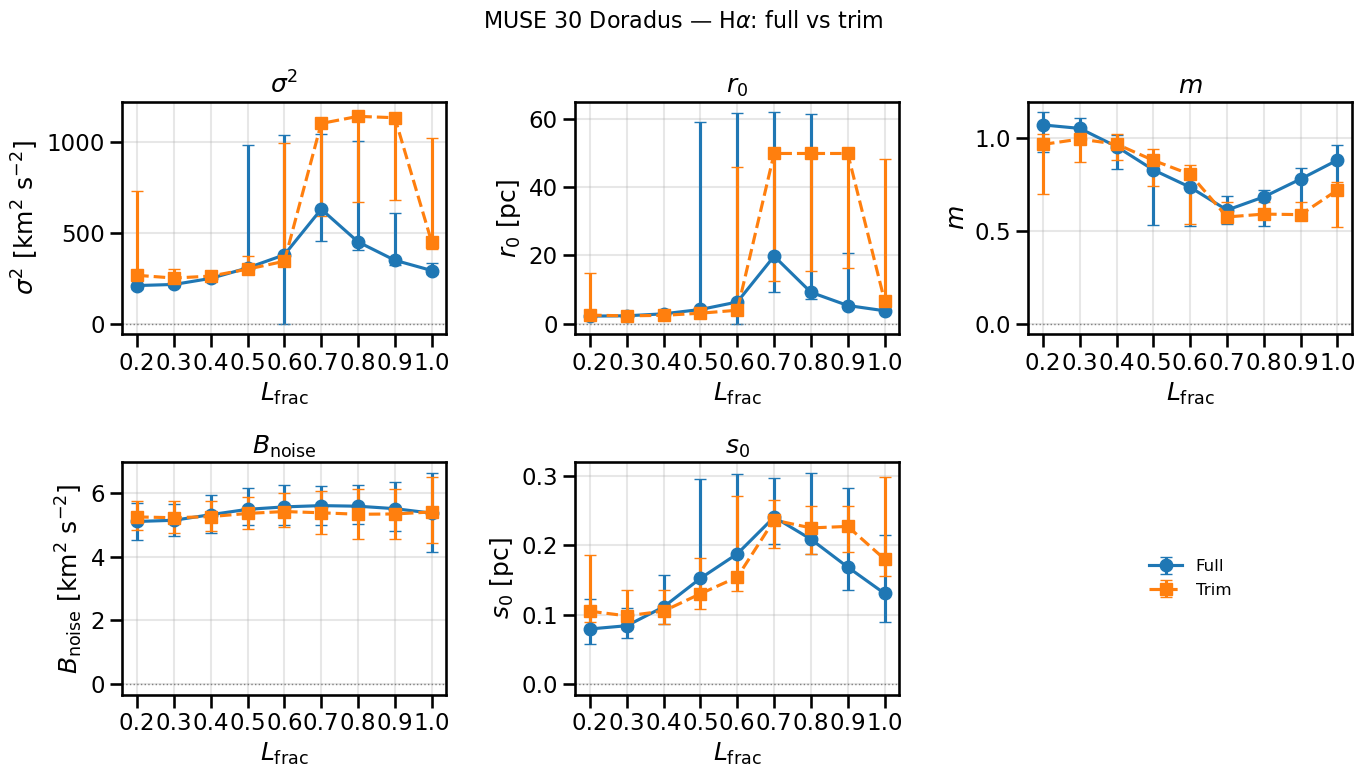

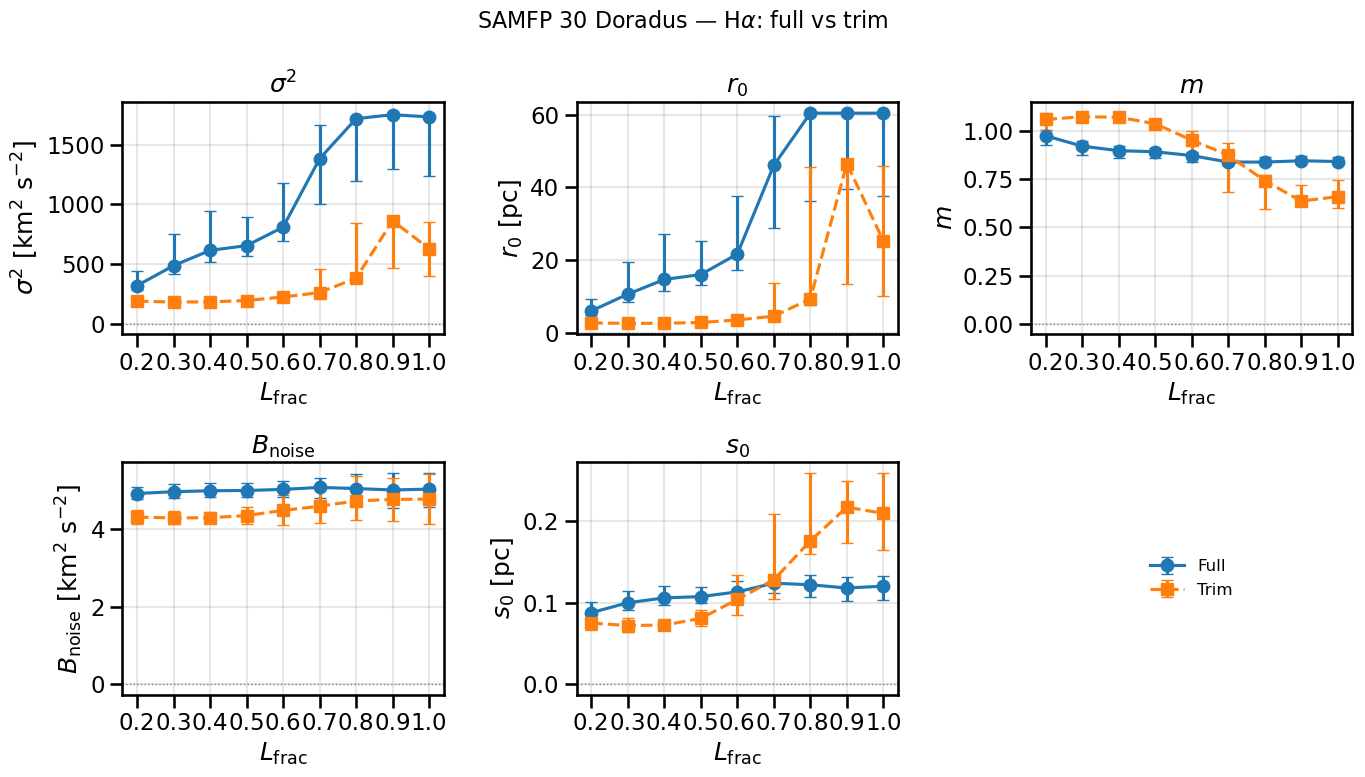

In [10]:
for instrument, groups in COMPARISON_GROUPS.items():

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    for ax, param in zip(axes, PARAMETERS):

        for group in groups:

            df_param = (
                fraction_table[
                    (fraction_table["parameter"] == param)
                    &
                    (fraction_table["group"] == group)
                ]
                .sort_values("fit_limit")
            )

            if df_param.empty:
                continue

            x = df_param["fit_limit"].to_numpy()
            y = df_param["value"].to_numpy(dtype=float)

            err_lower = df_param["err_lower"].to_numpy(dtype=float)
            err_upper = df_param["err_upper"].to_numpy(dtype=float)

            # Negative lower uncertainty:
            # plot the interval down to the physical boundary at zero.
            bad_lower = err_lower < 0

            err_lower_plot = np.where(
                bad_lower,
                y,
                np.abs(err_lower),
            )

            err_upper_plot = np.abs(
                err_upper
            )

            yerr = np.vstack([
                err_lower_plot,
                err_upper_plot,
            ])

            sample_type = (
                "Full"
                if group.endswith("-full")
                else "Trim"
            )

            marker = (
                "o"
                if sample_type == "Full"
                else "s"
            )

            linestyle = (
                "-"
                if sample_type == "Full"
                else "--"
            )

            ax.errorbar(
                x,
                y,
                yerr=yerr,
                marker=marker,
                linestyle=linestyle,
                capsize=4,
                label=sample_type,
            )

        ax.axhline(
            0.0,
            color="0.5",
            linestyle=":",
            linewidth=1.0,
        )

        ax.set_title(
            PARAM_TITLES[param]
        )

        ax.set_xlabel(
            r"$L_{\rm frac}$"
        )

        ax.set_ylabel(
            PARAM_LABELS[param]
        )

        ax.set_xticks(
            ALL_FIT_LIMITS
        )

        ax.grid(
            alpha=0.3
        )

    axes[-1].axis("off")

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    axes[-1].legend(
        handles,
        labels,
        loc="center",
        frameon=False,
        fontsize=12,
    )

    fig.suptitle(
        rf"{instrument} 30 Doradus — H$\alpha$: full vs trim",
        fontsize=16,
    )

    fig.tight_layout()

    fig.savefig(
        FIGS_DIR
        / f"{instrument}_30Dor_H_full_vs_trim_Lfrac.jpg",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


Visually indicate the fractions selected for the final result

In [11]:
# The adopted Lfrac values are defined independently
# for each of the seven samples in the next cell.


In [12]:
FIT_LIMITS_BY_GROUP = {
    # Full samples
    "MUSE-full": (
        0.2,
        0.3,
        0.4,
    ),

    "SAMFP-full": (
        0.2,
    ),

    # Trim samples
    "MUSE-trim": (
        0.3,
        0.4,
        0.5,
    ),

    "SAMFP-trim": (
        0.3,
        0.4,
        0.5,
    ),

    # Full FLAMES
    "FLAMES": (
        0.025,
        0.05,
        0.075,
    ),

    # MUSE-matched FLAMES trim
    "FLAMES-MUSE-trim": (
        0.3,
        0.4,
        0.5,
    ),

    # SAMFP-matched FLAMES trim
    "FLAMES-SAMFP-trim": (
        0.3,
        0.4,
        0.5,
    ),
}


The selected fractions are handled independently through
`FIT_LIMITS_BY_GROUP`.

The next diagnostic plots show the selected points and adopted result for each
of the seven samples, including separate diagnostics for:

- full FLAMES
- FLAMES-MUSE-trim
- FLAMES-SAMFP-trim

The two FLAMES trim samples share the regular \(0.3\)–\(1.0\) grid, while the
full FLAMES sample uses its separate \(0.025\)–\(0.20\) grid.


Downstream selection and averaging

In [13]:
selected_results_pc = (
    ffa.select_or_average_fit_results(
        all_fraction_results,
        fit_limits_by_group=FIT_LIMITS_BY_GROUP,
        group_keys=("group", "bin", "line"),
    )
)

selected_table_pc = ffa.results_to_dataframe(
    selected_results_pc
)

display(selected_table_pc)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,sig2,225.710123,32.431691,6.506103e+01,193.278431,290.771149,3
1,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,r0,2.529723,0.505398,1.287584e+00,2.024325,3.817306,3
2,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,m,1.023771,0.189899,1.137566e-01,0.833872,1.137527,3
3,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,noise,5.188290,0.673585,7.310408e-01,4.514705,5.919331,3
4,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,s0,0.091828,0.033868,6.554615e-02,0.057960,0.157374,3
5,SAMFP-full,0,H,0.2,"(0.2,)",single,sig2,320.553726,40.084629,1.231344e+02,280.469097,443.688104,1
6,SAMFP-full,0,H,0.2,"(0.2,)",single,r0,5.973963,1.011408,3.401995e+00,4.962555,9.375957,1
7,SAMFP-full,0,H,0.2,"(0.2,)",single,m,0.975209,0.049052,2.811520e-02,0.926156,1.003324,1
8,SAMFP-full,0,H,0.2,"(0.2,)",single,noise,4.909866,0.140099,1.554667e-01,4.769766,5.065333,1
9,SAMFP-full,0,H,0.2,"(0.2,)",single,s0,0.087726,0.007789,1.274940e-02,0.079937,0.100475,1


In [14]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

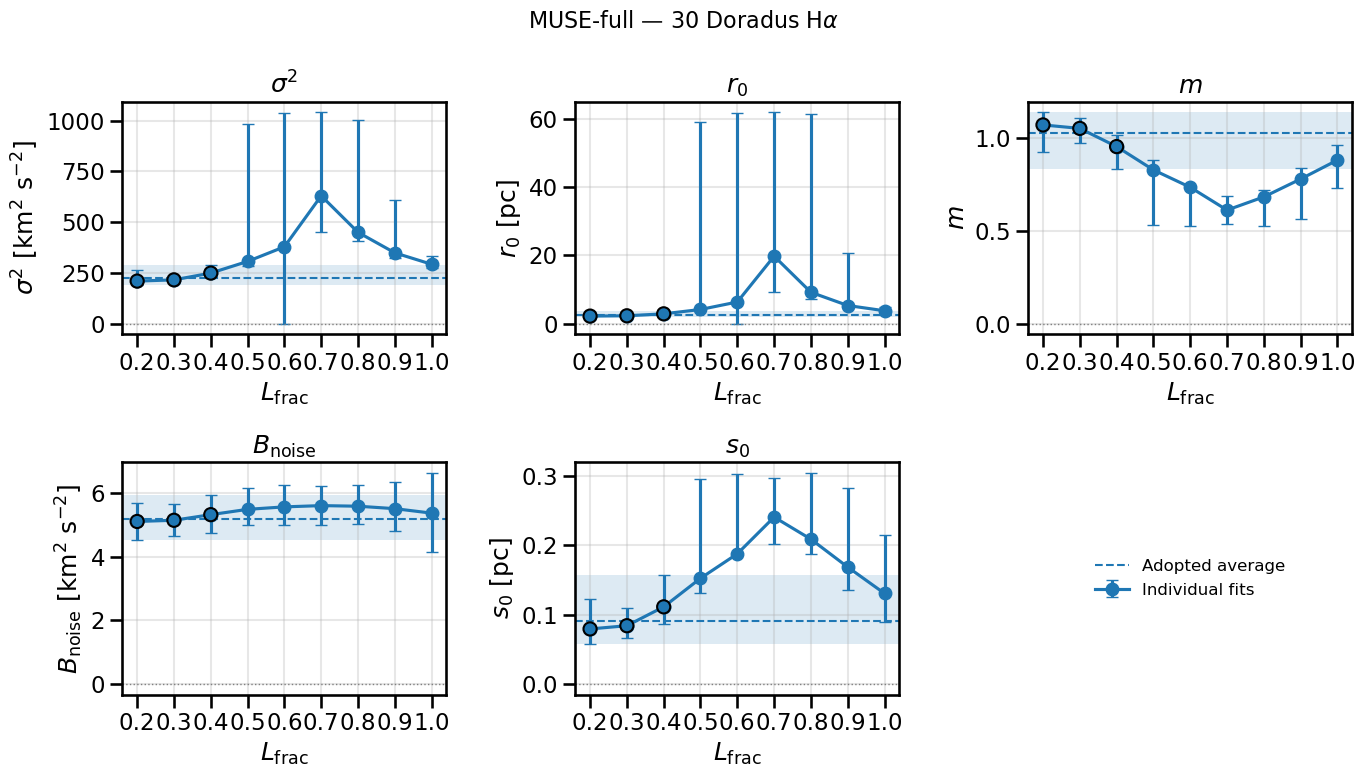

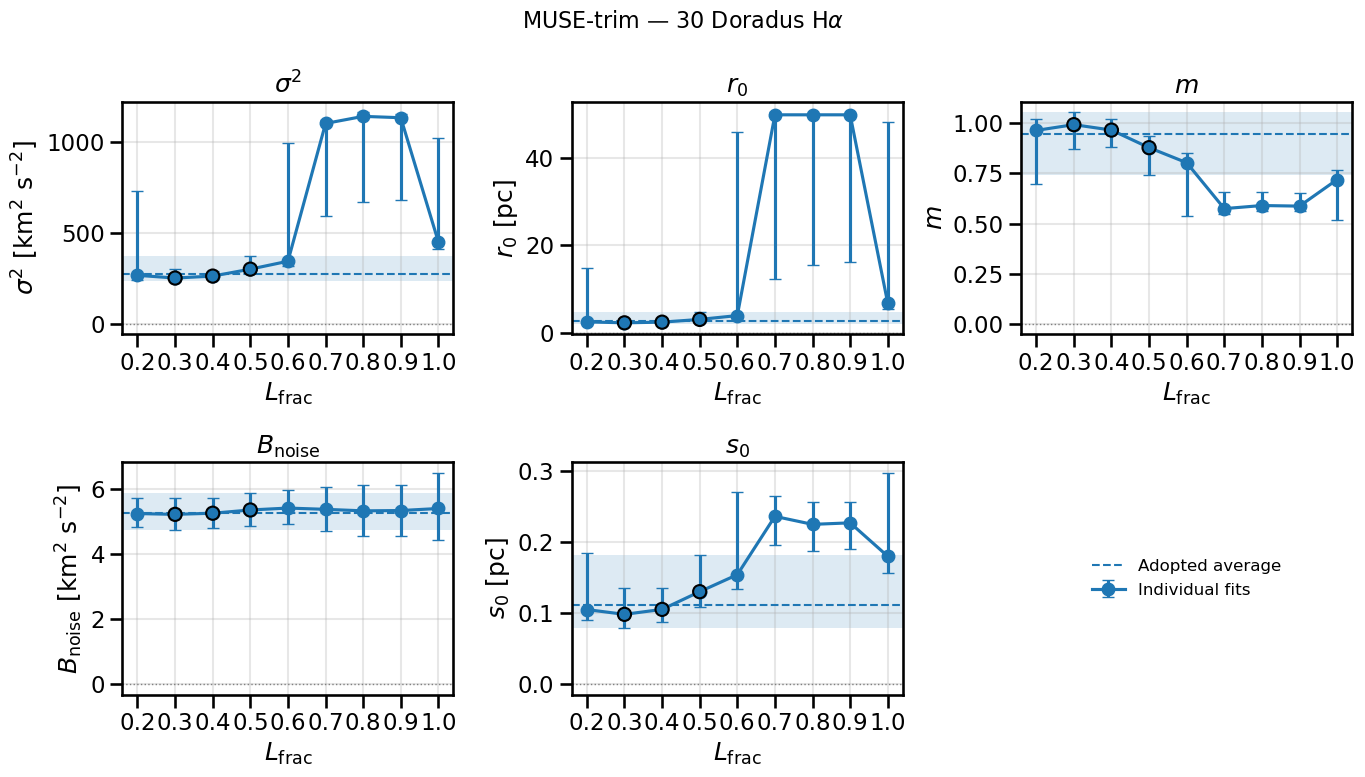

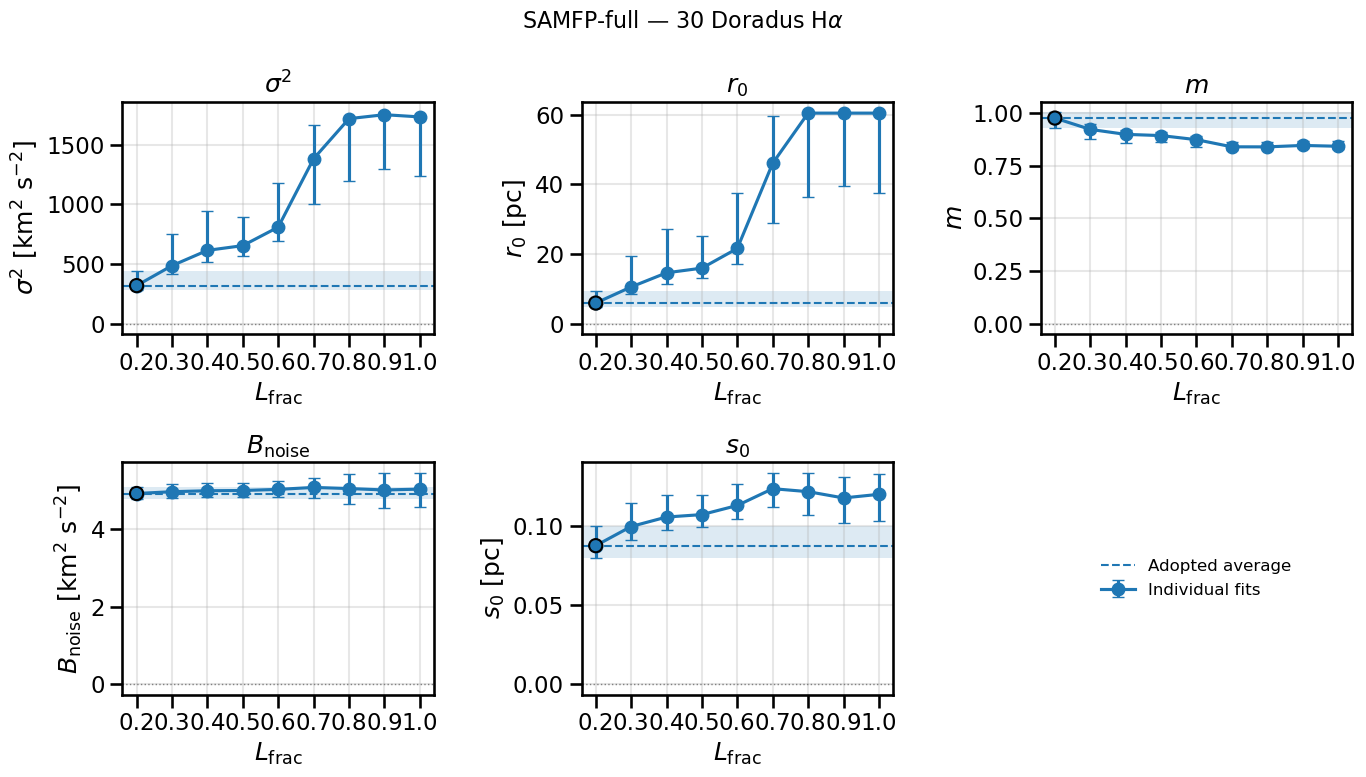

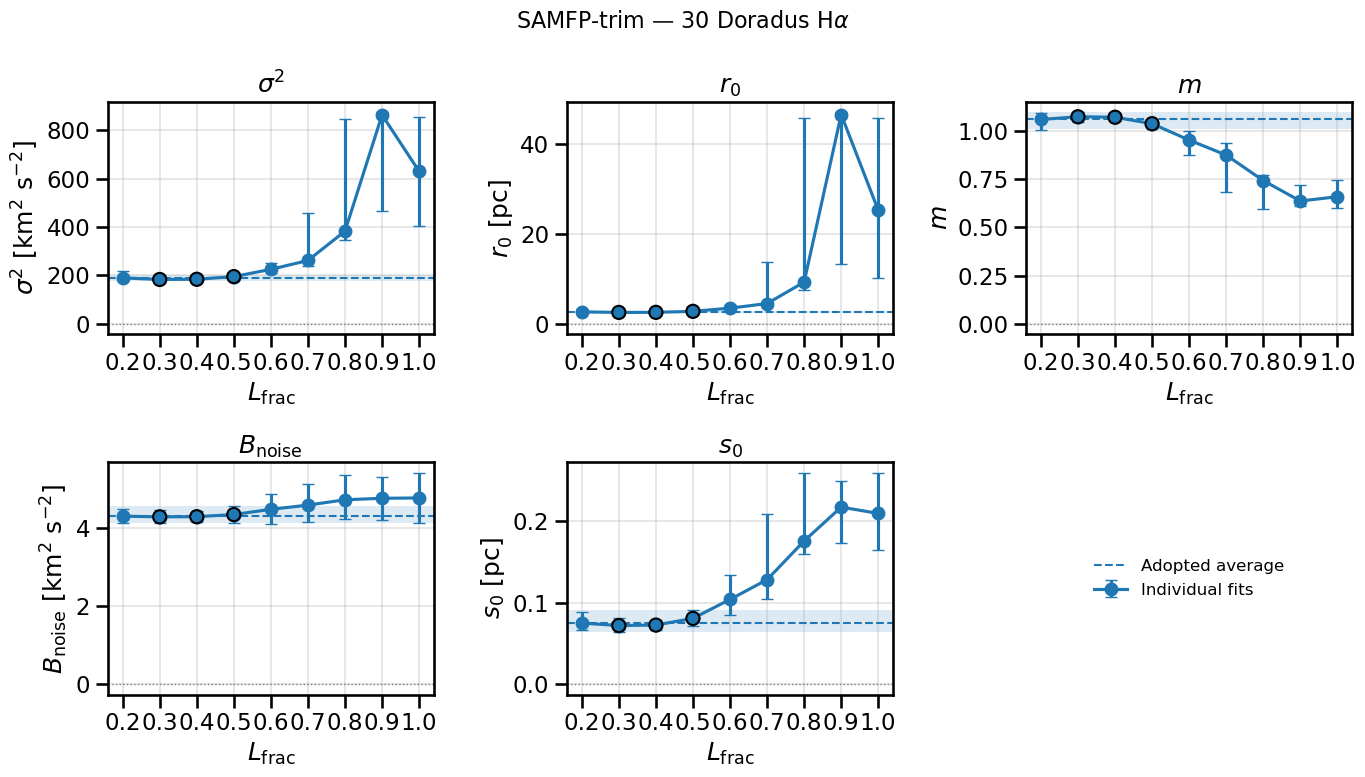

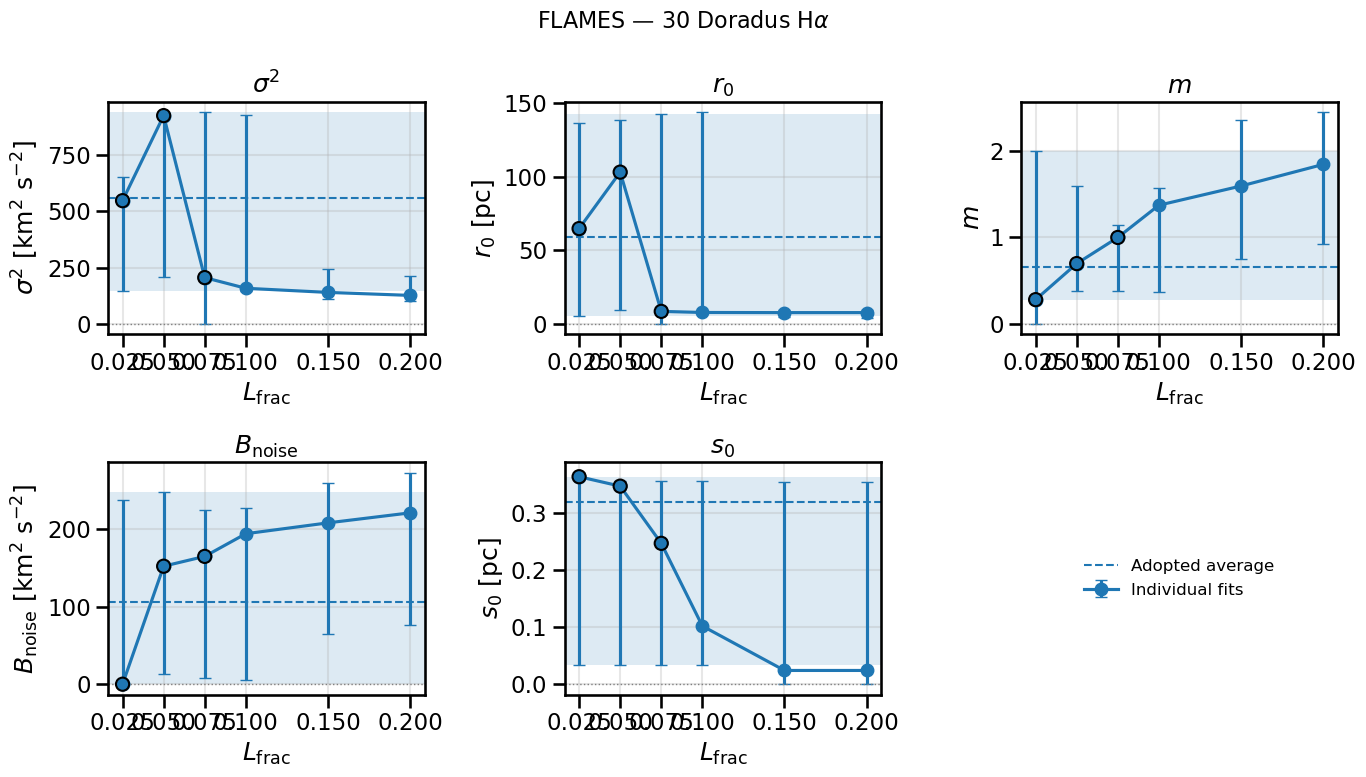

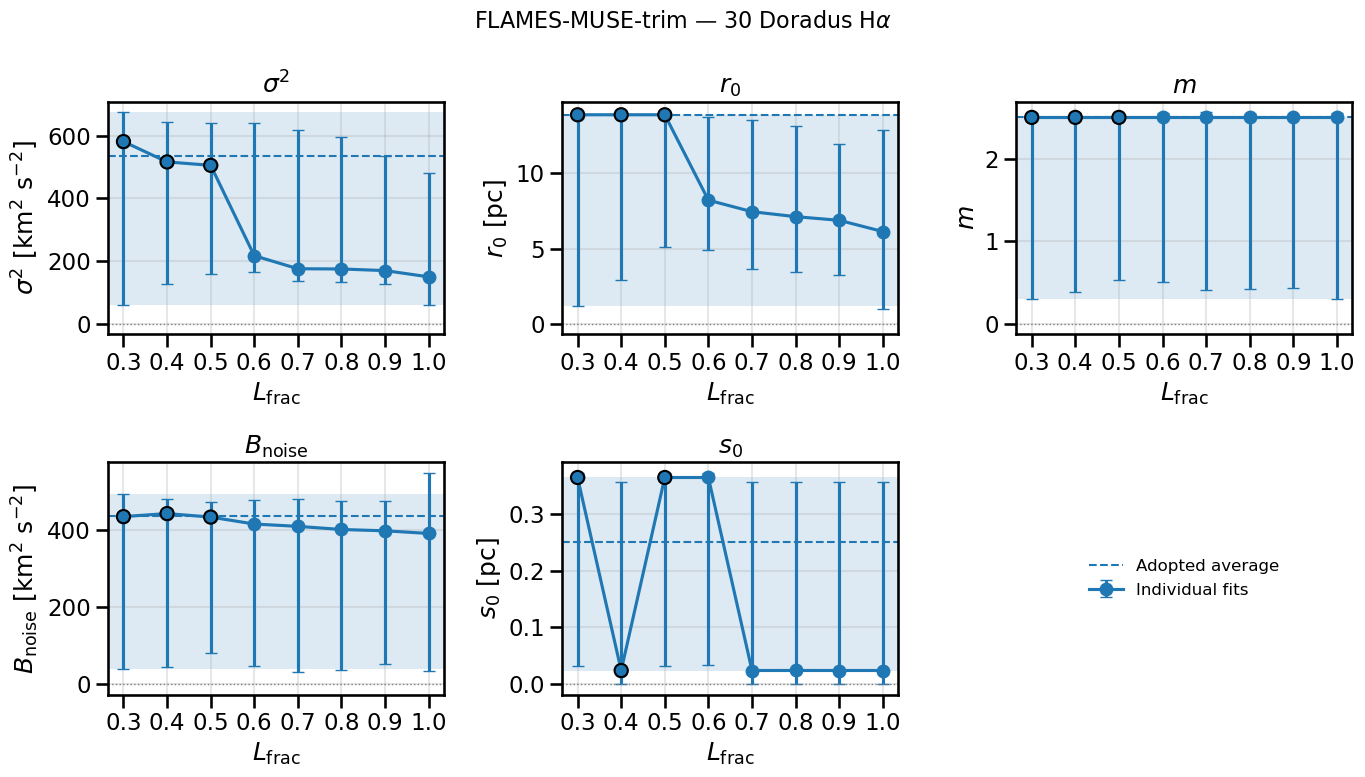

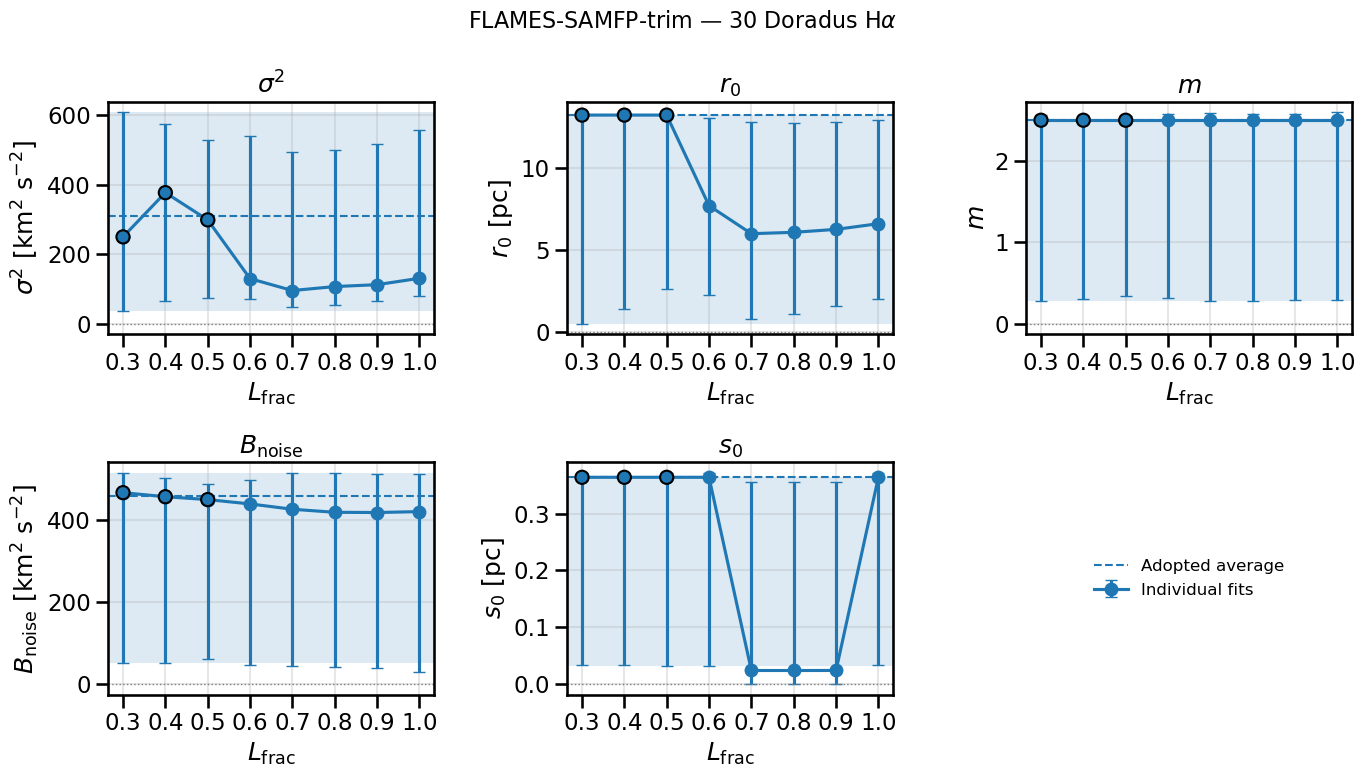

In [15]:
GROUPS_TO_PLOT = GROUP_ORDER

for group in GROUPS_TO_PLOT:

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    # Selected Lfrac values for this instrument
    selected_fit_limits = FIT_LIMITS_BY_GROUP[group]

    # Fit limits available for this instrument
    group_fit_limits = tuple(
        sorted(
            fraction_table.loc[
                fraction_table["group"] == group,
                "fit_limit",
            ].unique()
        )
    )

    for ax, param in zip(axes, PARAMETERS):

        # --------------------------------------------------
        # Complete Lfrac sample for this instrument
        # --------------------------------------------------
        df_raw = (
            fraction_table[
                (fraction_table["parameter"] == param)
                &
                (fraction_table["group"] == group)
            ]
            .sort_values("fit_limit")
        )

        x = df_raw["fit_limit"].to_numpy()
        y = df_raw["value"].to_numpy(dtype=float)

        err_lower = df_raw["err_lower"].to_numpy(dtype=float)
        err_upper = df_raw["err_upper"].to_numpy(dtype=float)

        # --------------------------------------------------
        # Error-bar treatment
        #
        # Negative lower uncertainties are interpreted as
        # extending to the physical boundary at zero.
        # --------------------------------------------------
        bad_lower = err_lower < 0

        err_lower_plot = np.where(
            bad_lower,
            y,
            np.abs(err_lower),
        )

        err_upper_plot = np.abs(
            err_upper
        )

        yerr = np.vstack([
            err_lower_plot,
            err_upper_plot,
        ])

        ax.errorbar(
            x,
            y,
            yerr=yerr,
            marker="o",
            linestyle="-",
            capsize=4,
            label="Individual fits",
        )

        # --------------------------------------------------
        # Selected / averaged result for this instrument
        # --------------------------------------------------
        df_avg = selected_table_pc[
            (selected_table_pc["parameter"] == param)
            &
            (selected_table_pc["group"] == group)
        ]

        if len(df_avg) == 1:

            avg = float(
                df_avg["value"].iloc[0]
            )

            avg_lower = float(
                df_avg["err_lower"].iloc[0]
            )

            avg_upper = float(
                df_avg["err_upper"].iloc[0]
            )

            # Same convention for a negative
            # lower uncertainty
            if avg_lower < 0:
                lower_limit = 0.0
            else:
                lower_limit = avg - abs(avg_lower)

            upper_limit = (
                avg + abs(avg_upper)
            )

            # Mean adopted value
            ax.axhline(
                avg,
                linestyle="--",
                linewidth=1.5,
                label="Adopted average",
            )

            # Full uncertainty envelope
            ax.axhspan(
                lower_limit,
                upper_limit,
                alpha=0.15,
            )

        # --------------------------------------------------
        # Mark selected Lfrac values
        # --------------------------------------------------
        selected_mask = (
            df_raw["fit_limit"]
            .isin(selected_fit_limits)
        )

        ax.scatter(
            df_raw.loc[
                selected_mask,
                "fit_limit",
            ],
            df_raw.loc[
                selected_mask,
                "value",
            ],
            s=90,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5,
            zorder=5,
        )

        # --------------------------------------------------
        # Reference line
        # --------------------------------------------------
        ax.axhline(
            0.0,
            color="0.5",
            linestyle=":",
            linewidth=1.0,
        )

        # --------------------------------------------------
        # Axes
        # --------------------------------------------------
        ax.set_title(
            PARAM_TITLES[param]
        )

        ax.set_xlabel(
            r"$L_{\rm frac}$"
        )

        ax.set_ylabel(
            PARAM_LABELS[param]
        )

        ax.set_xticks(
            group_fit_limits
        )

        ax.grid(
            alpha=0.3
        )

    # --------------------------------------------------
    # Legend in empty panel
    # --------------------------------------------------
    axes[-1].axis("off")

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    axes[-1].legend(
        handles,
        labels,
        loc="center",
        frameon=False,
        fontsize=12,
    )

    # --------------------------------------------------
    # Figure title
    # --------------------------------------------------
    fig.suptitle(
        rf"{group} — 30 Doradus H$\alpha$",
        fontsize=16,
    )

    fig.tight_layout()

    # --------------------------------------------------
    # Save
    # --------------------------------------------------
    fig.savefig(
        FIGS_DIR
        / f"{group}_30Dor_H_Lfrac_diagnostics.jpg",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

In [16]:
adopted_table = (
    selected_table_pc[
        [
            "group",
            "line",
            "fit_limits_used",
            "parameter",
            "value",
            "err_lower",
            "err_upper",
        ]
    ]
    .copy()
)

display(adopted_table)


,group,line,fit_limits_used,parameter,value,err_lower,err_upper
0,MUSE-full,H,"(0.2, 0.3, 0.4)",sig2,225.710123,32.431691,6.506103e+01
1,MUSE-full,H,"(0.2, 0.3, 0.4)",r0,2.529723,0.505398,1.287584e+00
2,MUSE-full,H,"(0.2, 0.3, 0.4)",m,1.023771,0.189899,1.137566e-01
3,MUSE-full,H,"(0.2, 0.3, 0.4)",noise,5.188290,0.673585,7.310408e-01
4,MUSE-full,H,"(0.2, 0.3, 0.4)",s0,0.091828,0.033868,6.554615e-02
5,SAMFP-full,H,"(0.2,)",sig2,320.553726,40.084629,1.231344e+02
6,SAMFP-full,H,"(0.2,)",r0,5.973963,1.011408,3.401995e+00
7,SAMFP-full,H,"(0.2,)",m,0.975209,0.049052,2.811520e-02
8,SAMFP-full,H,"(0.2,)",noise,4.909866,0.140099,1.554667e-01
9,SAMFP-full,H,"(0.2,)",s0,0.087726,0.007789,1.274940e-02


In [17]:
selected_results = ffa.convert_s0_pc_to_arcsec(
    selected_results_pc,
    fwhm_factor=2.355,
    copy=True,
)

selected_table = ffa.results_to_dataframe(
    selected_results
)

display(selected_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,sig2,225.710123,32.431691,6.506103e+01,193.278431,290.771149,3
1,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,r0,2.529723,0.505398,1.287584e+00,2.024325,3.817306,3
2,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,m,1.023771,0.189899,1.137566e-01,0.833872,1.137527,3
3,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,noise,5.188290,0.673585,7.310408e-01,4.514705,5.919331,3
4,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,s0,0.892114,0.329026,6.367855e-01,0.563088,1.528900,3
5,SAMFP-full,0,H,0.2,"(0.2,)",single,sig2,320.553726,40.084629,1.231344e+02,280.469097,443.688104,1
6,SAMFP-full,0,H,0.2,"(0.2,)",single,r0,5.973963,1.011408,3.401995e+00,4.962555,9.375957,1
7,SAMFP-full,0,H,0.2,"(0.2,)",single,m,0.975209,0.049052,2.811520e-02,0.926156,1.003324,1
8,SAMFP-full,0,H,0.2,"(0.2,)",single,noise,4.909866,0.140099,1.554667e-01,4.769766,5.065333,1
9,SAMFP-full,0,H,0.2,"(0.2,)",single,s0,0.852262,0.075672,1.238614e-01,0.776590,0.976123,1


In [18]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS_FINAL = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

# Combined adopted-result comparison

The next cells compare the adopted parameters for all seven samples:

- MUSE-full
- MUSE-trim
- SAMFP-full
- SAMFP-trim
- FLAMES
- FLAMES-MUSE-trim
- FLAMES-SAMFP-trim


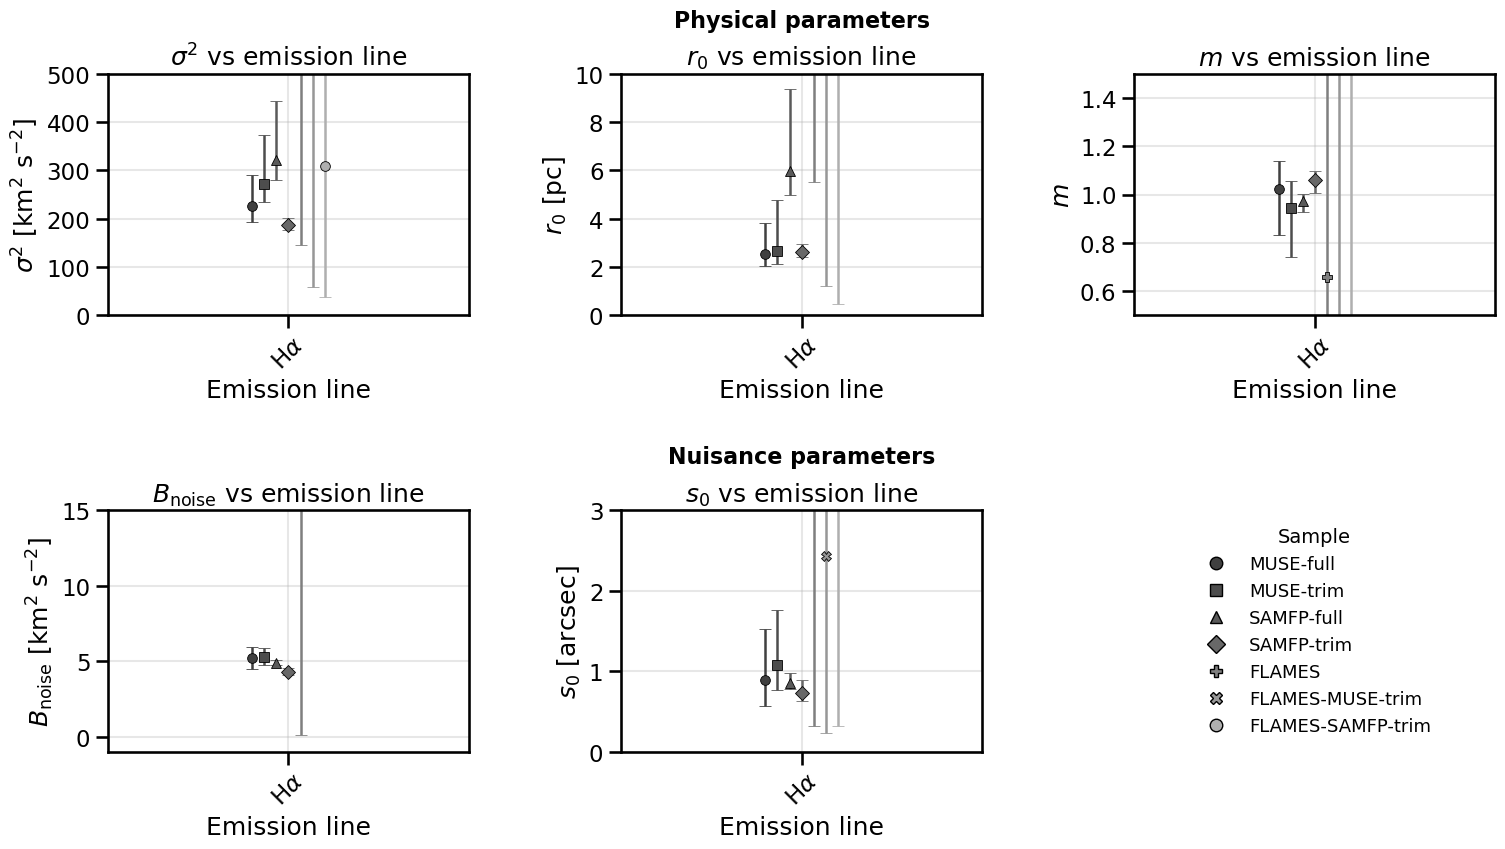

In [19]:
sample_selected = selected_results

# --------------------------------------------------
# Labels
# --------------------------------------------------

LINE_LABELS = {
    "H": r"H$\alpha$",
}

PARAM_LABELS_ARCSEC = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}


# --------------------------------------------------
# Plot adopted results for all seven samples
# --------------------------------------------------

fig_samples, axes_samples = ffa.plot_param_grid_lines_as_x(
    sample_selected,

    line_order=("H",),

    group_order=GROUP_ORDER,
    group_key="group",

    line_labels=LINE_LABELS,
    param_labels=PARAM_LABELS_ARCSEC,

    param_ylims={
        "sig2": (0, 500),
        "r0": (0, 10),
        "m": (0.5, 1.5),
        "noise": (-1, 15),
        "s0": (0, 3),
    },

    row_titles=(
        "Physical parameters",
        "Nuisance parameters",
    ),

    row_title_fontsize=16,
    figsize=(15, 9),

    jitter=0.10,

    save=True,
    savepath=(
        FIGS_DIR
        / "fit_fraction_average_full_trim_FLAMES_MUSE_SAMFP_trim.pdf"
    ),
)

# --------------------------------------------------
# Panel formatting
# --------------------------------------------------

for ax in axes_samples[:5]:
    ax.set_box_aspect(None)
    ax.set_aspect("auto")


fig_samples.subplots_adjust(
    left=0.065,
    right=0.99,
    wspace=0.42,
)

plt.show()


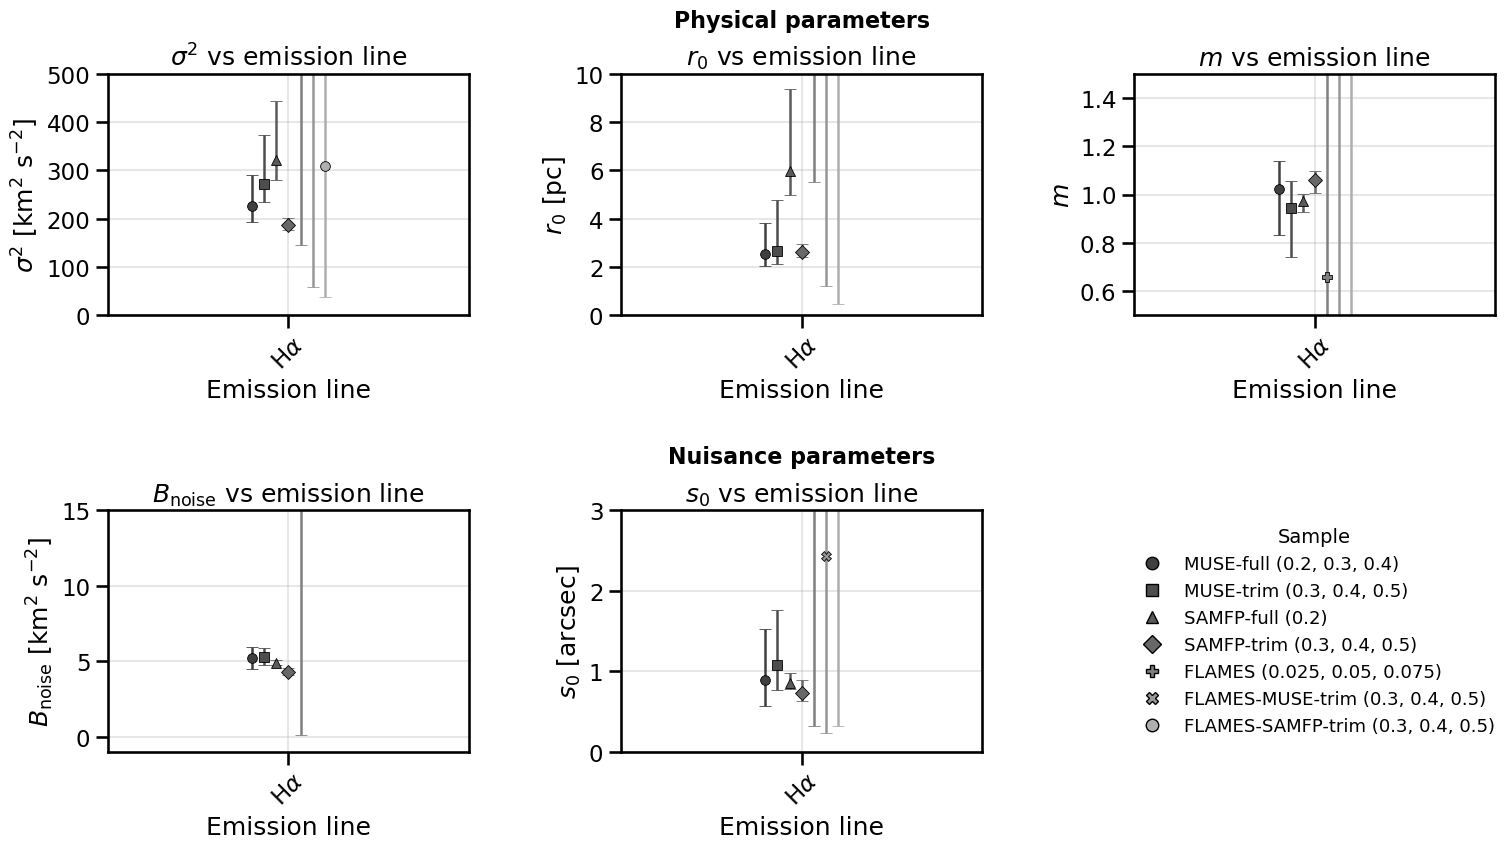

In [20]:
import copy

# --------------------------------------------------
# Copy selected results for plotting only
# --------------------------------------------------

sample_selected = copy.deepcopy(
    selected_results
)


# --------------------------------------------------
# Labels
# --------------------------------------------------

LINE_LABELS = {
    "H": r"H$\alpha$",
}

PARAM_LABELS_ARCSEC = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}


# --------------------------------------------------
# Group labels including adopted Lfrac values
# --------------------------------------------------

GROUP_LABELS = {}

for group in GROUP_ORDER:

    fit_limits = FIT_LIMITS_BY_GROUP[group]

    limits_text = ", ".join(
        f"{value:g}"
        for value in fit_limits
    )

    GROUP_LABELS[group] = (
        f"{group} ({limits_text})"
    )


# Replace group names only in plotting copy
for entry in sample_selected:

    original_group = entry["group"]

    entry["group"] = GROUP_LABELS[
        original_group
    ]


# Group order using display labels
GROUP_ORDER_PLOT = tuple(
    GROUP_LABELS[group]
    for group in GROUP_ORDER
)


# --------------------------------------------------
# Plot adopted results for all seven samples
# --------------------------------------------------

fig_samples, axes_samples = ffa.plot_param_grid_lines_as_x(
    sample_selected,

    line_order=("H",),

    group_order=GROUP_ORDER_PLOT,
    group_key="group",

    line_labels=LINE_LABELS,
    param_labels=PARAM_LABELS_ARCSEC,

    param_ylims={
        "sig2": (0, 500),
        "r0": (0, 10),
        "m": (0.5, 1.5),
        "noise": (-1, 15),
        "s0": (0, 3),
    },

    row_titles=(
        "Physical parameters",
        "Nuisance parameters",
    ),

    row_title_fontsize=16,
    figsize=(15, 9),

    jitter=0.10,

    save=True,
    savepath=(
        FIGS_DIR
        / "fit_fraction_average_full_trim_FLAMES_MUSE_SAMFP_trim.pdf"
    ),
)


# --------------------------------------------------
# Panel formatting
# --------------------------------------------------

for ax in axes_samples[:5]:
    ax.set_box_aspect(None)
    ax.set_aspect("auto")


fig_samples.subplots_adjust(
    left=0.065,
    right=0.99,
    wspace=0.42,
)

plt.show()

In [21]:
adopted_summary = (
    selected_table[
        [
            "group",
            "line",
            "fit_limits_used",
            "parameter",
            "value",
            "err_lower",
            "err_upper",
        ]
    ]
    .copy()
)

display(adopted_summary)

,group,line,fit_limits_used,parameter,value,err_lower,err_upper
0,MUSE-full,H,"(0.2, 0.3, 0.4)",sig2,225.710123,32.431691,6.506103e+01
1,MUSE-full,H,"(0.2, 0.3, 0.4)",r0,2.529723,0.505398,1.287584e+00
2,MUSE-full,H,"(0.2, 0.3, 0.4)",m,1.023771,0.189899,1.137566e-01
3,MUSE-full,H,"(0.2, 0.3, 0.4)",noise,5.188290,0.673585,7.310408e-01
4,MUSE-full,H,"(0.2, 0.3, 0.4)",s0,0.892114,0.329026,6.367855e-01
5,SAMFP-full,H,"(0.2,)",sig2,320.553726,40.084629,1.231344e+02
6,SAMFP-full,H,"(0.2,)",r0,5.973963,1.011408,3.401995e+00
7,SAMFP-full,H,"(0.2,)",m,0.975209,0.049052,2.811520e-02
8,SAMFP-full,H,"(0.2,)",noise,4.909866,0.140099,1.554667e-01
9,SAMFP-full,H,"(0.2,)",s0,0.852262,0.075672,1.238614e-01


Build the final adopted-parameter table

In [22]:
FINAL_PARAMETERS = (
    "sig2",
    "r0",
    "m",
    "noise",
    "s0",
)

available_groups = set(
    selected_table["group"]
)

FINAL_GROUP_ORDER = tuple(
    group
    for group in GROUP_ORDER
    if group in available_groups
)

final_rows = []

for group in FINAL_GROUP_ORDER:

    df_group = selected_table[
        selected_table["group"] == group
    ]

    if df_group.empty:
        continue

    row = {
        "group": group,
        "line": df_group["line"].iloc[0],
        "fit_limits_used":
            df_group["fit_limits_used"].iloc[0],
    }

    for param in FINAL_PARAMETERS:

        df_param = df_group[
            df_group["parameter"] == param
        ]

        if df_param.empty:
            continue

        values = df_param.iloc[0]

        row[param] = values["value"]
        row[f"{param}_err_lower"] = (
            values["err_lower"]
        )
        row[f"{param}_err_upper"] = (
            values["err_upper"]
        )

    final_rows.append(row)

final_table = pd.DataFrame(
    final_rows
)

display(final_table)


,group,line,fit_limits_used,sig2,sig2_err_lower,sig2_err_upper,r0,r0_err_lower,r0_err_upper,m,m_err_lower,m_err_upper,noise,noise_err_lower,noise_err_upper,s0,s0_err_lower,s0_err_upper
0,MUSE-full,H,"(0.2, 0.3, 0.4)",225.710123,32.431691,65.061026,2.529723,0.505398,1.287584,1.023771,0.189899,1.137566e-01,5.188290,0.673585,0.731041,0.892114,0.329026,6.367855e-01
1,MUSE-trim,H,"(0.3, 0.4, 0.5)",271.652340,38.033540,102.604528,2.657807,0.554782,2.104948,0.945571,0.204773,1.096665e-01,5.279045,0.530282,0.604269,1.082536,0.312120,6.835689e-01
2,SAMFP-full,H,"(0.2,)",320.553726,40.084629,123.134379,5.973963,1.011408,3.401995,0.975209,0.049052,2.811520e-02,4.909866,0.140099,0.155467,0.852262,0.075672,1.238614e-01
3,SAMFP-trim,H,"(0.3, 0.4, 0.5)",187.761235,10.441282,14.533879,2.639323,0.209298,0.313453,1.060890,0.053240,3.678564e-02,4.303543,0.188070,0.249528,0.729246,0.101443,1.572275e-01
4,FLAMES,H,"(0.025, 0.05, 0.075)",558.653430,412.965816,380.800604,58.862949,53.327504,83.665750,0.658065,0.378029,1.338023e+00,105.557953,105.443230,141.684567,3.101128,2.777285,4.313703e-01
5,FLAMES-MUSE-trim,H,"(0.3, 0.4, 0.5)",534.182874,474.647409,140.706181,13.889167,12.688840,0.000001,2.500000,2.198079,4.302692e-11,436.773325,396.175396,56.393602,2.433500,2.198000,1.099000e+00
6,FLAMES-SAMFP-trim,H,"(0.3, 0.4, 0.5)",308.768505,270.838519,299.832955,13.246572,12.780460,0.000048,2.500000,2.215357,4.134506e-10,458.833137,406.845444,57.041035,3.532500,3.213051,1.483061e-13


In [23]:
LATEX_LINE = "H"
LATEX_BIN = 0

latex_rows = []

for group in FINAL_GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=LATEX_BIN,
        line=LATEX_LINE,
    )

    row = ffa.format_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )

    latex_rows.append(row)

print("\n".join(latex_rows))

MUSE-full & 0 & H$\alpha$ & 0.2,0.3,0.4 & 225.71\PM{65.06}{32.43} & 2.530\PM{1.288}{0.505} & 1.02\PM{0.11}{0.19} & 5.188\PM{0.731}{0.674} & <1.53 & 9.33 & <0.0622 & 0.019 \\
MUSE-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 271.65\PM{102.60}{38.03} & 2.658\PM{2.105}{0.555} & 0.95\PM{0.11}{0.20} & 5.279\PM{0.604}{0.530} & <1.77 & 10.14 & <0.0684 & 0.018 \\
SAMFP-full & 0 & H$\alpha$ & 0.2 & 320.55\PM{123.13}{40.08} & 5.974\PM{3.402}{1.011} & 0.98\PM{0.03}{0.05} & 4.910\PM{0.155}{0.140} & <0.98 & 11.43 & <0.0168 & 0.007 \\
SAMFP-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 187.76\PM{14.53}{10.44} & 2.639\PM{0.313}{0.209} & 1.06\PM{0.04}{0.05} & 4.304\PM{0.250}{0.188} & <0.89 & 9.34 & <0.0346 & 0.017 \\
FLAMES & 0 & H$\alpha$ & 0.0,0.1,0.1 & 558.65\PM{380.80}{412.97} & 58.863\PM{83.666}{53.328} & 0.66\PM{1.34}{0.38} & 105.558\PM{141.685}{105.443} & <3.53 & 3.25 & <0.0062 & 0.000 \\
FLAMES-MUSE-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 534.18\PM{140.71}{474.65} & 13.889\PM{0.000}{12.689} & 2.50\PM{0.00}{2.20} 

In [24]:
for group in FINAL_GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=0,
        line="H",
    )

    print(f"\n--- {group} ---")

    ffa.print_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )


--- MUSE-full ---
MUSE-full & 0 & H$\alpha$ & 0.2,0.3,0.4 & 225.71\PM{65.06}{32.43} & 2.530\PM{1.288}{0.505} & 1.02\PM{0.11}{0.19} & 5.188\PM{0.731}{0.674} & <1.53 & 9.33 & <0.0622 & 0.019 \\

--- MUSE-trim ---
MUSE-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 271.65\PM{102.60}{38.03} & 2.658\PM{2.105}{0.555} & 0.95\PM{0.11}{0.20} & 5.279\PM{0.604}{0.530} & <1.77 & 10.14 & <0.0684 & 0.018 \\

--- SAMFP-full ---
SAMFP-full & 0 & H$\alpha$ & 0.2 & 320.55\PM{123.13}{40.08} & 5.974\PM{3.402}{1.011} & 0.98\PM{0.03}{0.05} & 4.910\PM{0.155}{0.140} & <0.98 & 11.43 & <0.0168 & 0.007 \\

--- SAMFP-trim ---
SAMFP-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 187.76\PM{14.53}{10.44} & 2.639\PM{0.313}{0.209} & 1.06\PM{0.04}{0.05} & 4.304\PM{0.250}{0.188} & <0.89 & 9.34 & <0.0346 & 0.017 \\

--- FLAMES ---
FLAMES & 0 & H$\alpha$ & 0.0,0.1,0.1 & 558.65\PM{380.80}{412.97} & 58.863\PM{83.666}{53.328} & 0.66\PM{1.34}{0.38} & 105.558\PM{141.685}{105.443} & <3.53 & 3.25 & <0.0062 & 0.000 \\

--- FLAMES-MUSE-trim ---
FLAM

Export the adopted sample

In [25]:
OUTPUT_TABLE = (
    OUTPUT_DIR
    / "fit_fraction_selected_results_full_trim_FLAMES_MUSE_SAMFP_trim.csv"
)

final_table.to_csv(
    OUTPUT_TABLE,
    index=False,
)

print(
    f"Saved table to {OUTPUT_TABLE}"
)


Saved table to C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\results_tables\full_trim_flames\fit_fraction_selected_results_full_trim_FLAMES_MUSE_SAMFP_trim.csv
